# Лабораторная работа 2. Классификация

**Задача:** по данным о пассажире Титаника предсказать, выжил он (`Survived = 1`) или нет (`Survived = 0`).

**Основная метрика:** F1-score для класса `Survived = 1` (порог: F1 > 0.70), дополнительные — Accuracy, Precision, Recall.

План работы:
1. Знакомство с данными (EDA) и выводы.
2. Подготовка данных и разбиение на train / test.
3. Baseline — всегда самый частый класс.
4. Метрики и confusion matrix.
5. Модели: Decision Tree, Random Forest, Gradient Boosting, SVM, KNN.
6. Честное сравнение моделей, итоговая таблица.
7. Feature importance.
8. Анализ ошибок лучшей модели.

In [1]:
import warnings
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

%matplotlib inline
sns.set(style="darkgrid")
pd.set_option("display.precision", 4)

RANDOM_STATE = 42

## 1. Знакомство с данными

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")
TARGET = "Survived"
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов без PassengerId:", df.drop(columns="PassengerId").duplicated().sum())
feat_cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin", "Embarked"]
same = df.fillna({"Age": -1, "Cabin": "NA", "Embarked": "NA"}).groupby(feat_cols)[TARGET].agg(["size", "nunique"])
print("Пассажиров, у которых признаки (без Name, Ticket, PassengerId) совпадают с кем-то ещё:", same.loc[same["size"] > 1, "size"].sum())
print("Из них в группах с разным Survived:", same.loc[same["nunique"] > 1, "size"].sum())

pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "пропусков": df.isna().sum(),
    "доля пропусков": df.isna().mean().round(3),
    "уникальных": df.nunique(),
})

Полных дубликатов строк: 0
Дубликатов без PassengerId: 0
Пассажиров, у которых признаки (без Name, Ticket, PassengerId) совпадают с кем-то ещё: 179
Из них в группах с разным Survived: 43


,тип,пропусков,доля пропусков,уникальных
PassengerId,int64,0,0.000,891
Survived,int64,0,0.000,2
Pclass,int64,0,0.000,3
Name,str,0,0.000,891
Sex,str,0,0.000,2
Age,float64,177,0.199,88
SibSp,int64,0,0.000,7
Parch,int64,0,0.000,7
Ticket,str,0,0.000,681
Fare,float64,0,0.000,248


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.0000,257.3538,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.3838,0.4866,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.3086,0.8361,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.6991,14.5265,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.5230,1.1027,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.3816,0.8061,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.2042,49.6934,0.00,7.9104,14.4542,31.0,512.3292


Что видно сразу:
- 891 пассажир, 10 признаков + `PassengerId` и целевая `Survived`. Числовые: `Pclass`, `Age`, `SibSp`, `Parch`, `Fare`; строковые: `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`.
- Пропуски: `Age` - 177 (20%), `Cabin` - 687 (77%), `Embarked` - 2. Их надо будет заполнять или как-то кодировать.
- Полных дубликатов нет. Но 179 пассажиров совпадают с кем-то ещё по всем признакам, кроме имени и билета (часто у них пропущен возраст), и 43 из них попали в группы, где один выжил, а другой нет. Различить таких пассажиров по нашим признакам нельзя, так что часть ошибок будет у любой модели.
- `PassengerId` и `Name` уникальны у всех, `Ticket` почти уникален (681 значение на 891 человека). Это скорее идентификаторы, чем признаки.
- `Fare` от 0 до 512 при медиане 14.5, сильный правый хвост. У 15 человек `Fare = 0`.

### Целевая переменная

Survived
0    0.616
1    0.384
Name: count, dtype: float64

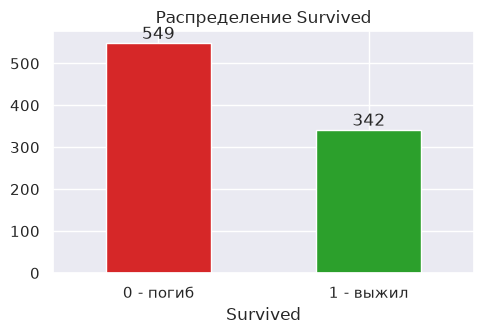

In [6]:
counts = df[TARGET].value_counts().sort_index()
ax = counts.plot.bar(figsize=(5, 3.5), rot=0, color=["tab:red", "tab:green"])
for i, c in enumerate(counts):
    ax.text(i, c, str(c), ha="center", va="bottom")
ax.set_title("Распределение Survived"); ax.set_xticklabels(["0 - погиб", "1 - выжил"])
plt.tight_layout()
(counts / len(df)).round(3)

Погибло 61.6%, выжило 38.4%, то есть классы не сбалансированы (примерно 1.6 к 1), но не сильно. Модель, которая всем говорит «погиб», уже получит Accuracy около 0.62 и при этом не найдёт ни одного выжившего. Поэтому основная метрика - F1 для класса 1, а не Accuracy.

### Признаки и выживаемость

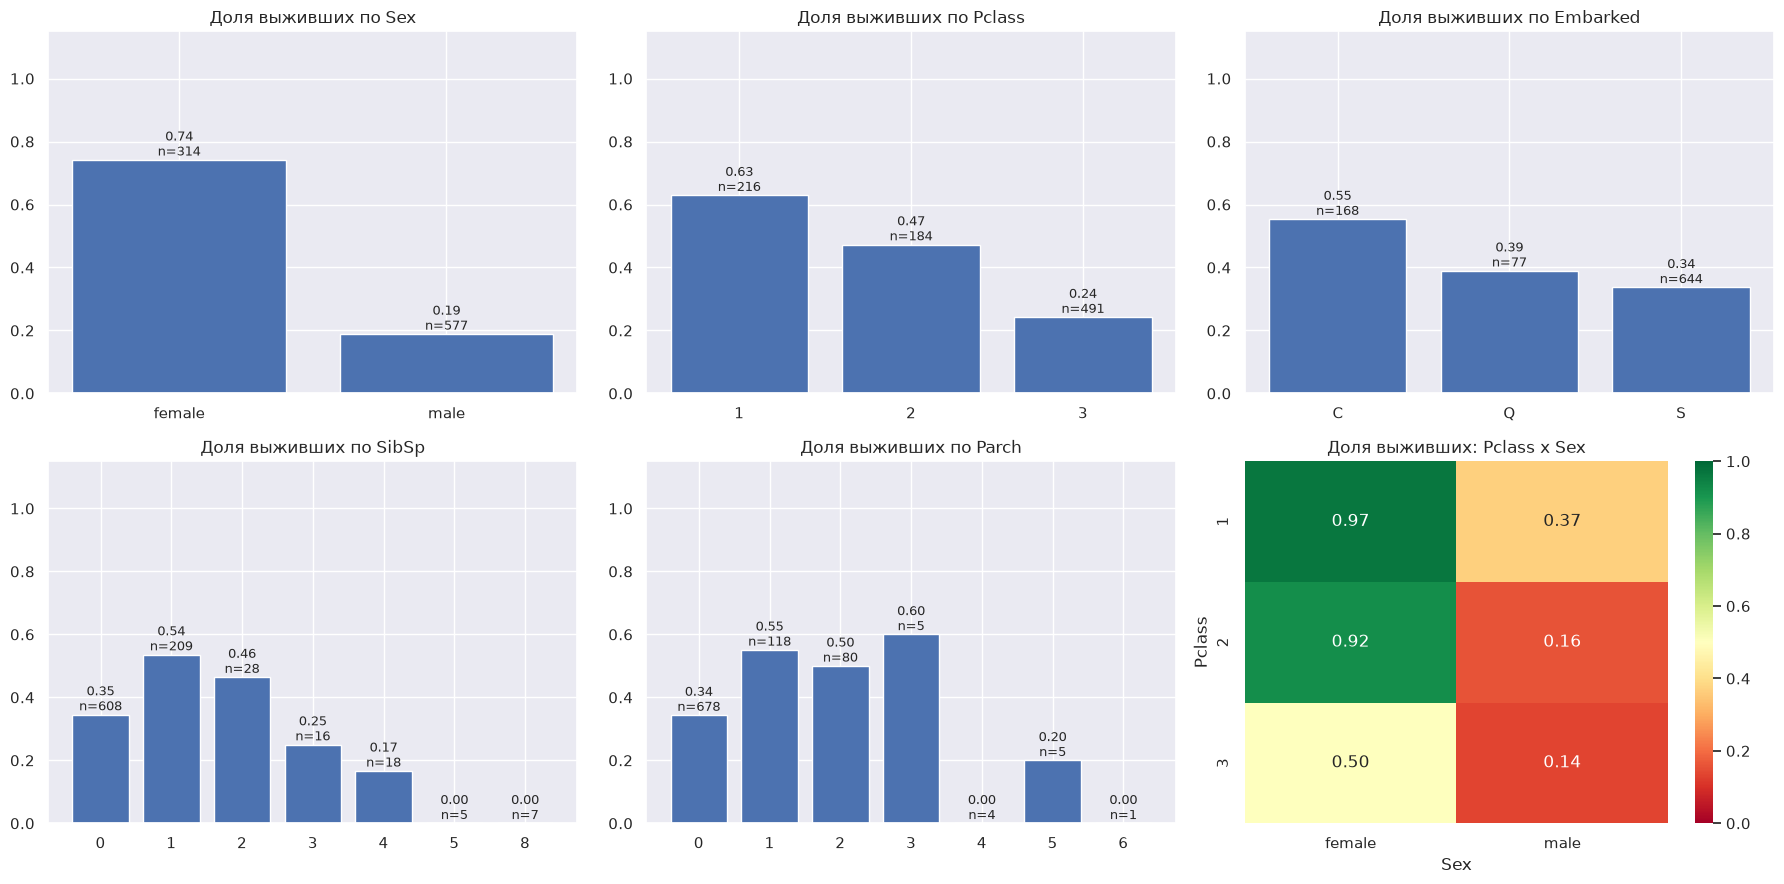

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axs.ravel(), ["Sex", "Pclass", "Embarked", "SibSp", "Parch"]):
    g = df.groupby(col)[TARGET].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"])
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m, f"{m:.2f}\nn={n}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, 1.15); ax.set_title(f"Доля выживших по {col}")
sns.heatmap(pd.crosstab(df["Pclass"], df["Sex"], values=df[TARGET], aggfunc="mean"),
            annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=axs[1, 2])
axs[1, 2].set_title("Доля выживших: Pclass x Sex")
plt.tight_layout()

           mean  size
Age                  
(0, 12]   0.580    69
(12, 18]  0.429    70
(18, 30]  0.356   270
(30, 45]  0.426   202
(45, 60]  0.407    81
(60, 80]  0.227    22

Fare: медиана у выживших 26.0, у погибших 10.5
Fare = 0: 15 пассажиров


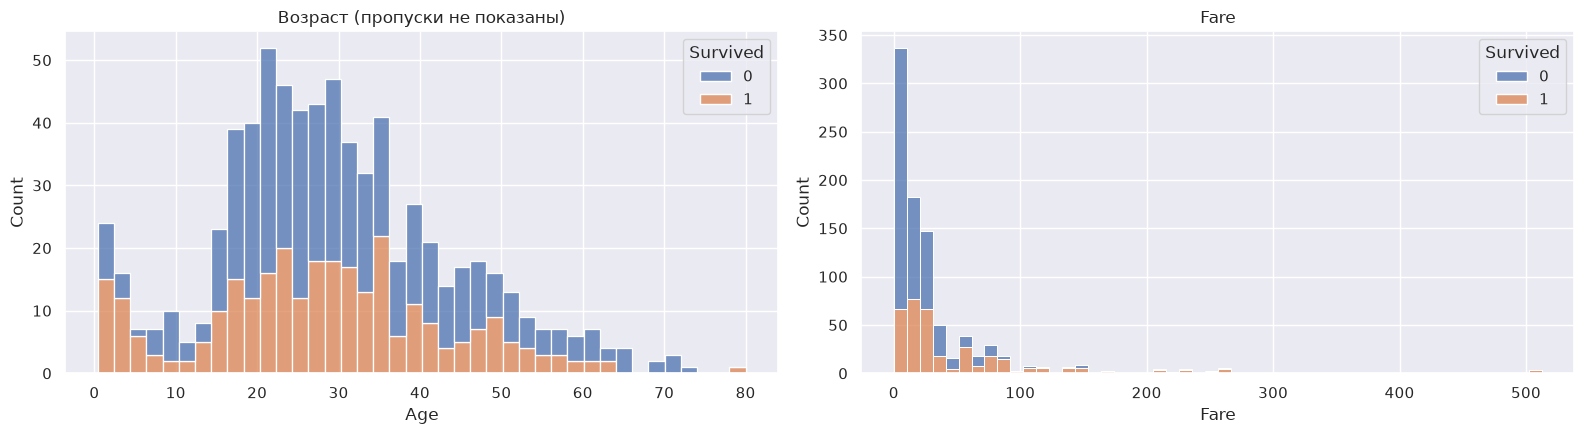

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(data=df, x="Age", hue=TARGET, bins=40, multiple="stack", ax=axs[0])
axs[0].set_title("Возраст (пропуски не показаны)")
sns.histplot(data=df, x="Fare", hue=TARGET, bins=50, multiple="stack", log_scale=(False, False), ax=axs[1])
axs[1].set_title("Fare")
plt.tight_layout()

age_bins = pd.cut(df["Age"], [0, 12, 18, 30, 45, 60, 80])
print(df.groupby(age_bins, observed=True)[TARGET].agg(["mean", "size"]).round(3))
print("\nFare: медиана у выживших %.1f, у погибших %.1f" % (df.loc[df[TARGET] == 1, "Fare"].median(),
                                                         df.loc[df[TARGET] == 0, "Fare"].median()))
print("Fare = 0:", (df["Fare"] == 0).sum(), "пассажиров")

### Признаки, которые требуют отдельной обработки

- `Name` — у каждого пассажира своё, но из него можно достать обращение (Mr, Mrs, Miss, Master...).
- `Cabin` — пропущено 77%, но сам факт, что номер каюты известен, может что-то значить.
- `Ticket` — почти уникальная строка.
- `Age` — 20% пропусков.

In [9]:
title = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
print(title.value_counts().to_dict())
df.assign(Title=title).groupby("Title").agg(n=(TARGET, "size"), survived=(TARGET, "mean"),
                                            age_median=("Age", "median"), age_missing=("Age", lambda a: a.isna().sum())) \
    .sort_values("n", ascending=False)

{'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Major': 2, 'Mlle': 2, 'Col': 2, 'Don': 1, 'Mme': 1, 'Ms': 1, 'Lady': 1, 'Sir': 1, 'Capt': 1, 'the Countess': 1, 'Jonkheer': 1}


,n,survived,age_median,age_missing
Title,,,,
Mr,517,0.1567,30.0,119
Miss,182,0.6978,21.0,36
Mrs,125,0.7920,35.0,17
Master,40,0.5750,3.5,4
Dr,7,0.4286,46.5,1
Rev,6,0.0000,46.5,0
Mlle,2,1.0000,24.0,0
Major,2,0.5000,48.5,0
Col,2,0.5000,58.0,0


In [10]:
print("Выживаемость: каюта известна %.3f, неизвестна %.3f" % (
    df.loc[df.Cabin.notna(), TARGET].mean(), df.loc[df.Cabin.isna(), TARGET].mean()))
print("Доля известных кают по классам:", df.groupby("Pclass")["Cabin"].apply(lambda c: c.notna().mean()).round(3).to_dict())
print("Выживаемость: возраст известен %.3f, неизвестен %.3f" % (
    df.loc[df.Age.notna(), TARGET].mean(), df.loc[df.Age.isna(), TARGET].mean()))
print("Доля пропусков Age по классам:", df.groupby("Pclass")["Age"].apply(lambda a: a.isna().mean()).round(3).to_dict())

ticket_size = df["Ticket"].map(df["Ticket"].value_counts())
print("\nУникальных билетов: %d из %d, пассажиров с общим билетом: %d" % (
    df["Ticket"].nunique(), len(df), (ticket_size > 1).sum()))

fam = df["SibSp"] + df["Parch"] + 1
print("\nВыживаемость по размеру семьи:")
print(df.groupby(fam)[TARGET].agg(["mean", "size"]).round(3).T)

Выживаемость: каюта известна 0.667, неизвестна 0.300
Доля известных кают по классам: {1: 0.815, 2: 0.087, 3: 0.024}
Выживаемость: возраст известен 0.406, неизвестен 0.294
Доля пропусков Age по классам: {1: 0.139, 2: 0.06, 3: 0.277}

Уникальных билетов: 681 из 891, пассажиров с общим билетом: 344

Выживаемость по размеру семьи:
           1        2        3       4     5       6       7    8    11
mean    0.304    0.553    0.578   0.724   0.2   0.136   0.333  0.0  0.0
size  537.000  161.000  102.000  29.000  15.0  22.000  12.000  6.0  7.0


Выводы:
- **Пол** - самый сильный признак: выжили 74% женщин и 19% мужчин («женщины и дети первыми»).
- **Класс** - второй: 63% / 47% / 24% для 1/2/3 класса. Вместе с полом картина ещё резче: женщины 1 и 2 класса выжили почти все (97% и 92%), женщины 3 класса - только половина, мужчины 2 и 3 класса - 14-16%. Сложнее всего будет с женщинами 3 класса (50 на 50) и мужчинами 1 класса (37%).
- **Возраст** сам по себе связан слабо: дети до 12 лет выживали чаще (58%), люди старше 60 реже (23%), а в середине почти без разницы.
- **Fare**: у выживших медиана 26, у погибших 10.5. Но это в основном тот же класс. Распределение сильно скошено, поэтому для SVM и KNN беру log(1 + Fare).
- **Embarked**: из Шербура (C) выжило 55%, из Саутгемптона (S) 34%. Скорее всего тоже через класс, в Шербуре садилось много пассажиров 1 класса. Сам порт вряд ли на что-то влиял.
- **Семья**: одиночки выживали в 30% случаев, семьи из 2-4 человек в 55-72%, большие семьи (5+) почти все погибли. Зависимость не монотонная, поэтому добавлю `FamilySize` и `IsAlone`.

Признаки, которые надо обрабатывать отдельно:
- **`Name`**: само имя у всех разное, использовать его нельзя - модель просто запомнит пассажиров. Но в нём есть обращение (`Title`), и оно очень информативное: Mr выжили 16%, Mrs 79%, Miss 70%, Master (мальчики, медиана возраста 3.5 года) 57.5%. Обращение сразу кодирует пол, возраст и семейное положение. Редких обращений (Dr, Rev, Col, Countess...) всего 23 человека, их объединю в `Rare`.
- **`Cabin`**: номер каюты почти уникален и известен только у 23%. Но если каюта известна, выжило 67%, а если нет - 30%. Причём каюта известна у 82% пассажиров 1 класса и у 2% третьего, то есть это опять в основном класс. Беру только флаг `HasCabin`.
- **`Age`**: пропуски не случайные - у 28% пассажиров 3 класса возраст неизвестен (в 1 классе 14%), и среди них выжило 29% против 41%. Поэтому заполняю пропуски и добавляю флаг `AgeMissing`.
- **`Ticket`**: 681 уникальное значение, общий билет у 344 человек (обычно семьи). Если дать его модели, она может запомнить «эта семья погибла» и угадать родственника в тесте. Но это не закономерность, а запоминание конкретных людей, и на новых пассажирах это не сработает. Не использую.
- **`PassengerId`** - просто номер строки, смысла нет, не использую.

Признаков, которые прямо содержат ответ (например, номер шлюпки или номер найденного тела, они есть в расширенных версиях датасета), здесь нет.

## 2. Подготовка данных и выборок

Что делаю с признаками:
- `PassengerId`, `Ticket` убираю. Из `Name` беру только `Title` (Mlle и Ms -> Miss, Mme -> Mrs, остальные редкие -> Rare). Из `Cabin` только `HasCabin`.
- `Sex` -> `IsMale` (0/1).
- `FamilySize = SibSp + Parch + 1` и `IsAlone`.
- `Fare` -> `LogFare = log(1 + Fare)`: убирает длинный хвост и нормально работает с нулями. Деревьям всё равно (порядок значений не меняется), а для SVM и KNN выбросы перестают сильно влиять на расстояния.
- `Age`: заполняю медианой по `Title`, а не общей медианой. Иначе мальчик (Master) без возраста получил бы 28 лет и выглядел как взрослый мужчина. Плюс флаг `AgeMissing`.
- `Embarked`: пропусков 2, заполняю самым частым значением.
- `Embarked` и `Title` - категории без порядка, кодирую one-hot. `Pclass` оставляю числом, у классов есть порядок (1 лучше 2, 2 лучше 3).

Всё, что считается по данным (медианы возраста, самое частое `Embarked`, one-hot, масштабирование), сидит внутри `Pipeline`. Поэтому оно обучается только на train, а при кросс-валидации - только на обучающих фолдах. `add_features` работает построчно и ничего не учит, его можно применять к любым данным.

Делю 80/20 со стратификацией по `Survived` и `random_state=42`: в train 712 пассажиров, в test 179, доля выживших в обоих 38.4%. Разбиение одно для всех моделей. Тест использую только для финальной оценки, параметры подбираю на кросс-валидации (StratifiedKFold, 5 фолдов) по F1.

In [11]:
TITLE_MAP = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
MAIN_TITLES = ["Mr", "Mrs", "Miss", "Master"]


def add_features(data):
    # построчные преобразования, ничего не учится по данным
    d = pd.DataFrame(index=data.index)
    title = data["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip().replace(TITLE_MAP)
    d["Title"] = title.where(title.isin(MAIN_TITLES), "Rare")
    d["Pclass"] = data["Pclass"]
    d["IsMale"] = (data["Sex"] == "male").astype(int)
    d["Age"] = data["Age"]
    d["SibSp"] = data["SibSp"]
    d["Parch"] = data["Parch"]
    d["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
    d["LogFare"] = np.log1p(data["Fare"])
    d["HasCabin"] = data["Cabin"].notna().astype(int)
    d["Embarked"] = data["Embarked"]
    return d


class AgeByTitleImputer(BaseEstimator, TransformerMixin):
    # заполняет Age медианой по Title; медианы считаются только по данным из fit (train)
    def fit(self, X, y=None):
        self.medians_ = X.groupby("Title")["Age"].median()
        self.global_median_ = X["Age"].median()
        return self

    def transform(self, X):
        X = X.copy()
        X["AgeMissing"] = X["Age"].isna().astype(int)
        X["Age"] = X["Age"].fillna(X["Title"].map(self.medians_)).fillna(self.global_median_)
        return X

    def set_output(self, *, transform=None):
        return self  # и так возвращает DataFrame


NUM_COLS = ["Pclass", "IsMale", "Age", "AgeMissing", "SibSp", "Parch", "FamilySize", "IsAlone", "LogFare", "HasCabin"]
CAT_COLS = ["Embarked", "Title"]


def make_prep(scale=False, features=add_features, extra_num=()):
    num = StandardScaler() if scale else "passthrough"
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    if scale:
        cat.steps.append(("scaler", StandardScaler()))
    return Pipeline([
        ("features", FunctionTransformer(features)),
        ("age", AgeByTitleImputer()),
        ("ct", ColumnTransformer([("num", num, NUM_COLS + list(extra_num)), ("cat", cat, CAT_COLS)],
                                 verbose_feature_names_out=False).set_output(transform="pandas")),
    ])


def make_model(model, scale=False):
    return Pipeline([("prep", make_prep(scale)), ("model", model)])


# исходные колонки, которые подаём на вход; PassengerId и Ticket не используем
RAW_COLS = ["Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin", "Embarked"]
X = df[RAW_COLS]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("train:", X_train.shape, " test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).round(4)

train: (712, 9)  test: (179, 9)


,train,test
Survived,,
0,0.6166,0.6145
1,0.3834,0.3855


In [12]:
# как выглядят данные после подготовки (prep обучен только на train)
prep = make_prep().fit(X_train)
X_train_prep = prep.transform(X_train)
FEATURES = list(X_train_prep.columns)
print(len(FEATURES), "признаков:", FEATURES)
print("Медианы Age по Title (train):", prep.named_steps["age"].medians_.to_dict())
X_train_prep.head()

18 признаков: ['Pclass', 'IsMale', 'Age', 'AgeMissing', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'LogFare', 'HasCabin', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']
Медианы Age по Title (train): {'Master': 3.0, 'Miss': 22.0, 'Mr': 30.0, 'Mrs': 35.0, 'Rare': 49.0}


,Pclass,IsMale,Age,AgeMissing,SibSp,Parch,FamilySize,IsAlone,LogFare,HasCabin,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
692,3,1,30.0,1,0,0,1,1,4.0517,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
481,2,1,30.0,1,0,0,1,1,0.0000,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
527,1,1,30.0,1,0,0,1,1,5.4062,1,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
855,3,0,18.0,0,0,1,2,0,2.3370,0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
801,2,0,31.0,0,1,1,3,0,3.3051,0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


**Для каких алгоритмов важно масштабирование?**

- **Decision Tree, Random Forest, Gradient Boosting** - не нужно. Дерево в каждом узле сравнивает один признак с порогом, и если признак умножить или сдвинуть, порог просто сдвинется, а разбиение будет тем же.
- **SVM (RBF-ядро) и KNN** - нужно. Они работают с расстояниями между объектами. Без масштабирования `Age` (от 0 до 80) и `FamilySize` (до 11) почти целиком определяют расстояние, а разница по полу (0/1) почти ничего не значит, хотя это самый важный признак. Ниже проверю это на CV.

Поэтому для SVM и KNN в pipeline добавляю `StandardScaler` (после one-hot, чтобы все признаки были в одном масштабе), для деревьев нет.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cv_f1(model):
    # средний F1 на кросс-валидации по train
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    return scores.mean(), scores.std()


def tune(model, grid):
    search = GridSearchCV(model, grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    std = search.cv_results_["std_test_score"][search.best_index_]
    print("Лучшие параметры:", search.best_params_, " CV F1 = %.4f ± %.4f" % (search.best_score_, std))
    return search


results = {}
models = {}


def scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }


def evaluate(name, model, cv_score=np.nan, plot=True):
    # оценка на тесте, для всех моделей одинаковая; train - для проверки переобучения
    models[name] = model
    pred = model.predict(X_test)
    tr = scores(y_train, model.predict(X_train))
    results[name] = {**scores(y_test, pred), "CV F1": cv_score, "Train Accuracy": tr["Accuracy"], "Train F1": tr["F1"]}
    r = results[name]
    print(f"{name}: Accuracy = {r['Accuracy']:.4f}, Precision = {r['Precision']:.4f}, "
          f"Recall = {r['Recall']:.4f}, F1 = {r['F1']:.4f}")
    print(f"{' ' * len(name)}  train: Accuracy = {tr['Accuracy']:.4f}, F1 = {tr['F1']:.4f}")
    if plot:
        cm = confusion_matrix(y_test, pred)
        fig, ax = plt.subplots(figsize=(4, 3.5))
        ConfusionMatrixDisplay(cm, display_labels=["погиб", "выжил"]).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(name); ax.grid(False)
        plt.tight_layout(); plt.show()
        tn, fp, fn, tp = cm.ravel()
        print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

## 3. Метрики

Положительный класс - «выжил» (1).

- **TP** - предсказали «выжил», и он выжил; **TN** - предсказали «погиб», и он погиб.
- **FP** (ложная тревога) - предсказали «выжил», а пассажир погиб.
- **FN** (пропуск) - предсказали «погиб», а пассажир на самом деле выжил.

$$\text{Accuracy} = \frac{TP + TN}{n}, \quad \text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}, \quad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

- **Accuracy** - доля верных ответов. При 62% погибших константа «погиб» уже даёт 0.62, поэтому одна Accuracy мало что говорит.
- **Precision** - из тех, кого модель назвала выжившими, сколько выжило на самом деле. Падает из-за FP.
- **Recall** - какую долю настоящих выживших модель нашла. Падает из-за FN.
- **F1** - среднее гармоническое Precision и Recall. Оно маленькое, если маленькое хотя бы одно из них, поэтому F1 нельзя «накрутить», предсказывая всем один класс.

**Чем отличаются FP и FN в этой задаче?** FP - модель считает, что человек спасся, а он погиб. FN - модель «хоронит» человека, который на самом деле выжил. Что хуже, зависит от того, для чего нужна модель. Если, например, по ней решать, кого искать среди спасённых или кому из родственников сообщать о гибели, то FN хуже: живого человека посчитали погибшим. Если оценивать, кому нужна помощь после катастрофы, то FP хуже - человек остался без внимания, потому что модель решила, что он в безопасности. F1 учитывает оба типа ошибок, поэтому подходит, когда нет причины сильно предпочитать один из них.

## 4. Baseline

Baseline (most frequent): Accuracy = 0.6145, Precision = 0.0000, Recall = 0.0000, F1 = 0.0000
                          train: Accuracy = 0.6166, F1 = 0.0000


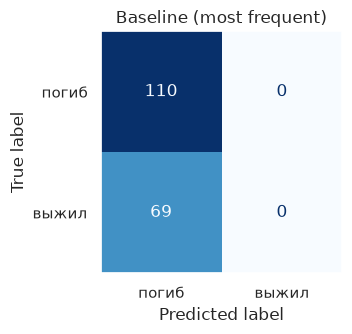

TN = 110, FP = 0, FN = 69, TP = 0


In [14]:
dummy = make_model(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
evaluate("Baseline (most frequent)", dummy, cv_f1(dummy)[0])

Baseline всем говорит «погиб»: Accuracy 0.6145 (ровно доля погибших в test), а Precision, Recall и F1 равны 0, он не нашёл ни одного из 69 выживших (все они FN). То есть по F1 любая осмысленная модель будет лучше, а вот по Accuracy реальную пользу показывает только то, что выше 0.61.

## 5. Модели

### 5.1 Decision Tree

Сначала дерево без ограничений (по умолчанию растёт, пока листья не станут чистыми), потом подбираю глубину и размер листа по CV.

Глубина: 23, листьев: 157


CV F1 = 0.7161 ± 0.0103
Decision Tree (без ограничений): Accuracy = 0.7933, Precision = 0.7353, Recall = 0.7246, F1 = 0.7299
                                 train: Accuracy = 0.9874, F1 = 0.9833


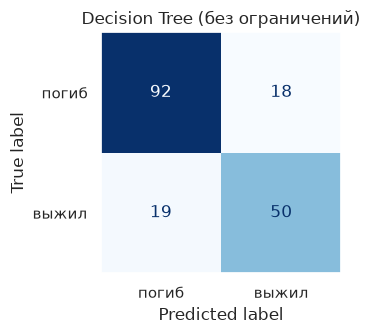

TN = 92, FP = 18, FN = 19, TP = 50


In [15]:
dt_full = make_model(DecisionTreeClassifier(random_state=RANDOM_STATE)).fit(X_train, y_train)
print("Глубина: %d, листьев: %d" % (dt_full[-1].get_depth(), dt_full[-1].get_n_leaves()))
print("CV F1 = %.4f ± %.4f" % cv_f1(dt_full))
evaluate("Decision Tree (без ограничений)", dt_full, cv_f1(dt_full)[0])

In [16]:
dt_search = tune(
    make_model(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "model__min_samples_leaf": [1, 3, 5, 10, 20]},
)
res = pd.DataFrame(dt_search.cv_results_)
res.pivot_table(index="param_model__max_depth", columns="param_model__min_samples_leaf", values="mean_test_score", dropna=False)

Лучшие параметры: {'model__max_depth': 3, 'model__min_samples_leaf': 1}  CV F1 = 0.7619 ± 0.0469


param_model__min_samples_leaf,1,3,5,10,20
param_model__max_depth,,,,,
2.0,0.6889,0.6889,0.6889,0.6889,0.6889
3.0,0.7619,0.7619,0.7597,0.7526,0.7455
4.0,0.7529,0.7575,0.7530,0.7325,0.7279
5.0,0.7421,0.7475,0.7484,0.7444,0.7279
6.0,0.7277,0.7350,0.7329,0.7352,0.7279
8.0,0.7280,0.7483,0.7297,0.7314,0.7279
10.0,0.7259,0.7434,0.7324,0.7314,0.7279
NaN,0.7161,0.7337,0.7348,0.7314,0.7279


Глубина: 3, листьев: 8
Decision Tree: Accuracy = 0.8324, Precision = 0.8197, Recall = 0.7246, F1 = 0.7692
               train: Accuracy = 0.8315, F1 = 0.7683


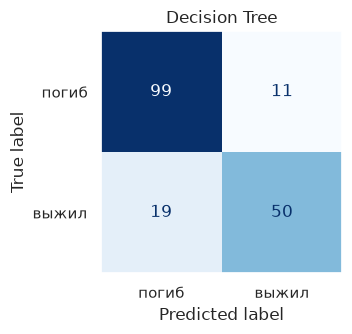

TN = 99, FP = 11, FN = 19, TP = 50


In [17]:
dt = dt_search.best_estimator_
print("Глубина: %d, листьев: %d" % (dt[-1].get_depth(), dt[-1].get_n_leaves()))
evaluate("Decision Tree", dt, dt_search.best_score_)

In [18]:
# train vs test для обоих деревьев
pd.DataFrame(results).T.loc[["Decision Tree (без ограничений)", "Decision Tree"],
                            ["Train Accuracy", "Accuracy", "Train F1", "CV F1", "F1"]]

,Train Accuracy,Accuracy,Train F1,CV F1,F1
Decision Tree (без ограничений),0.9874,0.7933,0.9833,0.7161,0.7299
Decision Tree,0.8315,0.8324,0.7683,0.7619,0.7692


Title_Mr      0.6298
Pclass        0.1555
FamilySize    0.0825
Title_Rare    0.0615
HasCabin      0.0504
Age           0.0130
LogFare       0.0075
IsMale        0.0000
dtype: float64

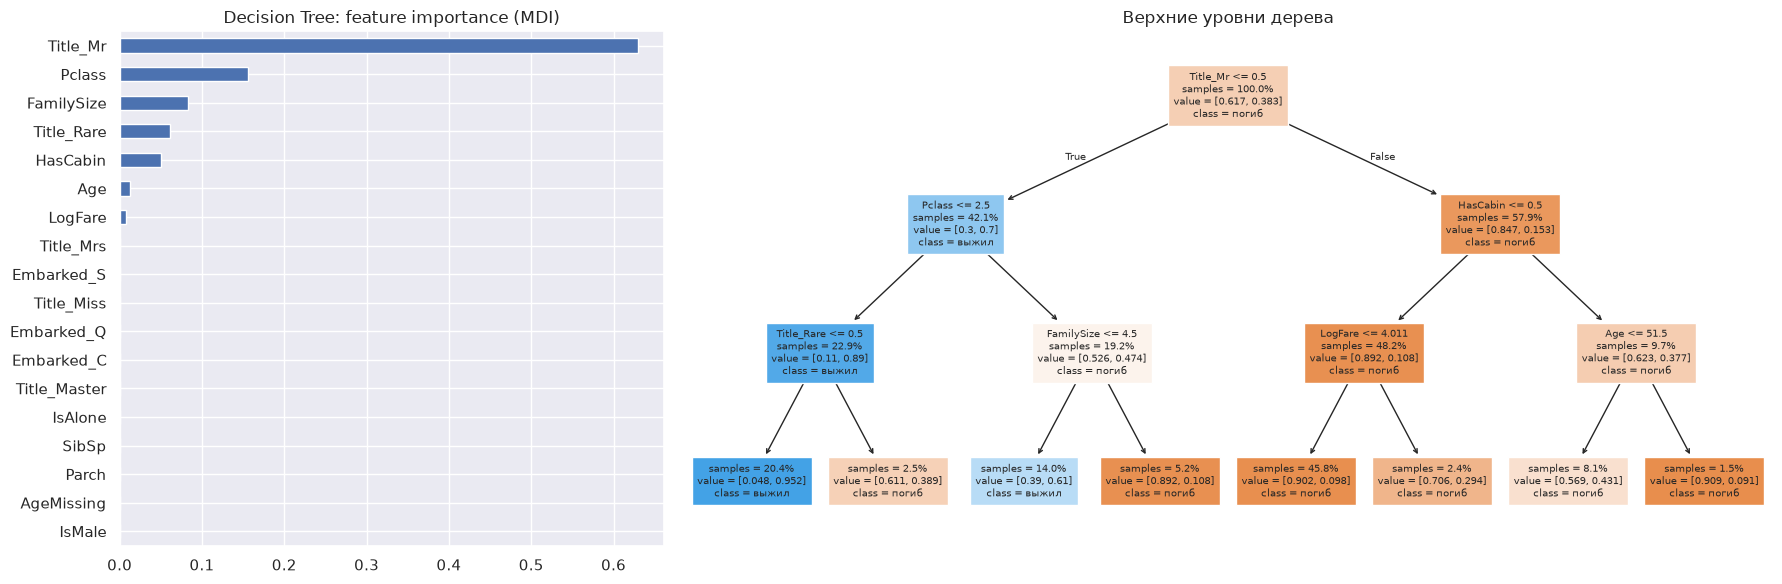

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 2]})
dt_imp = pd.Series(dt[-1].feature_importances_, index=FEATURES).sort_values()
dt_imp.plot.barh(ax=axs[0], title="Decision Tree: feature importance (MDI)")
plot_tree(dt[-1], feature_names=FEATURES, class_names=["погиб", "выжил"], max_depth=3,
          filled=True, impurity=False, proportion=True, fontsize=7, ax=axs[1])
axs[1].set_title("Верхние уровни дерева")
plt.tight_layout()
dt_imp.sort_values(ascending=False).head(8)

Что получилось:
- **Дерево без ограничений** выросло до глубины 23 и 157 листьев. На train Accuracy 0.987 и F1 0.983, а на test 0.793 и 0.730, на CV F1 0.716. Это явное переобучение: дерево запомнило train, включая шум. До 1.0 на train не дошло только потому, что там есть пассажиры с одинаковыми признаками и разным исходом.
- **Подобранное дерево** (`max_depth=3`, 8 листьев): CV F1 0.762, train F1 0.768, test F1 0.769, Accuracy на train и test одинаковая (0.83). Разрыва между train и test нет, значит переобучения нет. На тесте F1 0.769, порог пройден. Ограничение глубины сильно помогло: на CV +0.05 F1 к неограниченному дереву.
- Ошибки на тесте: 19 FN (пропустило 19 из 69 выживших) и 11 FP. FN больше, модель скорее «хоронит» лишних.
- **Как дерево решает:** первый вопрос - `Title_Mr` (взрослый мужчина или нет). Все листья для Mr предсказывают «погиб». Для остальных (женщины и мальчики) дальше смотрит на класс: в 1-2 классе выжило 89% (без `Rare` 95%). В 3 классе решает размер семьи: при `FamilySize <= 4` выжило 61%, у больших семей 11%. Это почти дословно выводы из EDA.
- **Feature importance**: `Title_Mr` 0.63, `Pclass` 0.16, `FamilySize` 0.08, `Title_Rare` 0.06, `HasCabin` 0.05. У `IsMale` важность 0, но это не значит, что пол не важен: `Title_Mr` уже содержит пол (и возраст), и после первого разбиения `IsMale` ничего не добавляет. MDI у коррелирующих признаков делится случайно и для одиночного дерева нестабилен.

### 5.2 Random Forest

Много деревьев на бутстреп-выборках со случайным подмножеством признаков в каждом сплите, ответ - голосование. Масштабирование не нужно.

In [20]:
rf_search = tune(
    make_model(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
    {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 2, 4],
     "model__max_features": ["sqrt", 0.5]},
)
pd.DataFrame(rf_search.cv_results_)[["param_model__max_depth", "param_model__min_samples_leaf",
                                     "param_model__max_features", "mean_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(8)

Лучшие параметры: {'model__max_depth': 4, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2}  CV F1 = 0.7800 ± 0.0391


,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,mean_test_score
1,4,2,sqrt,0.7800
0,4,1,sqrt,0.7778
2,4,4,sqrt,0.7754
3,4,1,0.5,0.7648
15,8,1,0.5,0.7646
5,4,4,0.5,0.7639
19,None,2,sqrt,0.7636
16,8,2,0.5,0.7629


Random Forest: Accuracy = 0.8045, Precision = 0.7742, Recall = 0.6957, F1 = 0.7328
               train: Accuracy = 0.8399, F1 = 0.7824


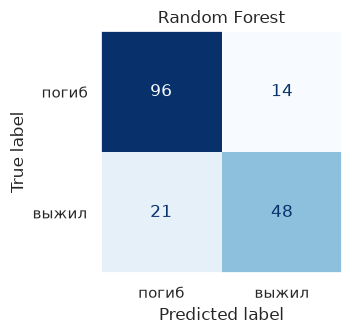

TN = 96, FP = 14, FN = 21, TP = 48


In [21]:
rf = rf_search.best_estimator_
evaluate("Random Forest", rf, rf_search.best_score_)

,Decision Tree,Random Forest
IsMale,0.0000,0.2516
Title_Mr,0.6298,0.2156
LogFare,0.0075,0.0907
Pclass,0.1555,0.0820
HasCabin,0.0504,0.0702
Title_Miss,0.0000,0.0669
Title_Mrs,0.0000,0.0572
FamilySize,0.0825,0.0494
Age,0.0130,0.0405
SibSp,0.0000,0.0218


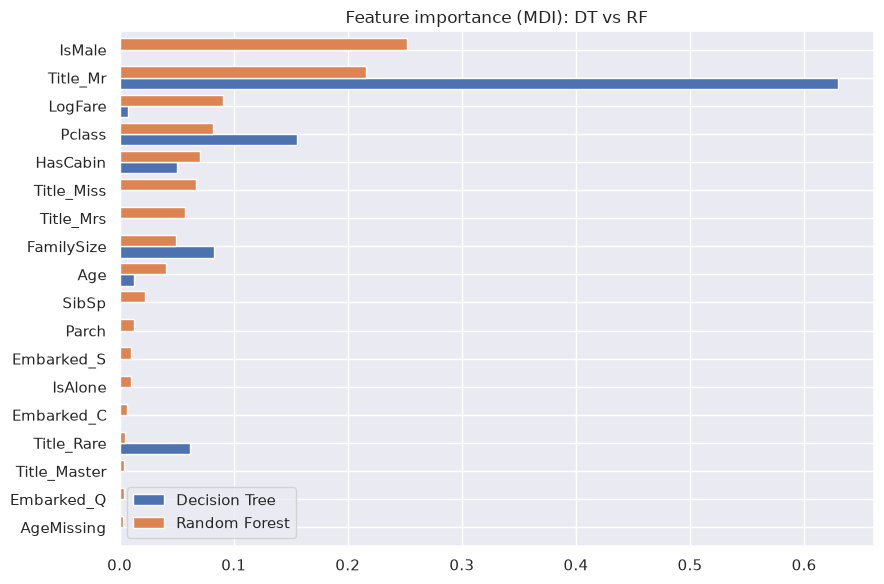

In [22]:
rf_imp = pd.Series(rf[-1].feature_importances_, index=FEATURES)
imp = pd.DataFrame({"Decision Tree": dt_imp, "Random Forest": rf_imp}).sort_values("Random Forest")
imp.plot.barh(figsize=(9, 6), width=0.8, title="Feature importance (MDI): DT vs RF")
plt.tight_layout()
imp.sort_values("Random Forest", ascending=False).head(10)

- Лучшие параметры: `max_depth=4`, `max_features="sqrt"`, `min_samples_leaf=2`. CV F1 0.780 ± 0.039, это лучший результат на CV из всех моделей. Глубокий лес на CV хуже (0.764 без ограничения глубины): данных мало и в них много шума, и даже усреднение 300 деревьев не убирает переобучение полностью.
- На тесте Accuracy 0.805, Precision 0.774, Recall 0.696, F1 0.733, порог пройден. Train F1 0.782, то есть почти как CV. На тесте немного хуже, чем на CV, но в тесте всего 69 выживших и одна ошибка меняет F1 примерно на 0.01, так что это в пределах разброса (std на CV 0.04).
- FN 21, FP 14 - тоже больше пропусков, чем ложных тревог.
- **Важность признаков по сравнению с деревом**: топ тот же (пол/обращение, класс, каюта, семья), но у леса важность распределена ровнее: `IsMale` 0.25, `Title_Mr` 0.22, `LogFare` 0.09, `Pclass` 0.08, `HasCabin` 0.07, `Title_Miss` и `Title_Mrs` по 0.06-0.07. Причина в том, что в каждом узле лес выбирает из случайной части признаков. Когда `Title_Mr` недоступен, дерево берёт `IsMale` или `Title_Mrs`, и важность делится между ними. Так же делятся `Pclass`, `LogFare` и `HasCabin`, которые все про класс и достаток.

### 5.3 Gradient Boosting

Деревья строятся по очереди, каждое следующее исправляет ошибки предыдущих. Сначала параметры по умолчанию, потом подбор по CV.

In [23]:
gb_default = make_model(GradientBoostingClassifier(random_state=RANDOM_STATE))
print("GB (default: 100 деревьев, depth=3, lr=0.1) CV F1 = %.4f ± %.4f" % cv_f1(gb_default))

gb_search = tune(
    make_model(GradientBoostingClassifier(subsample=0.8, random_state=RANDOM_STATE)),
    {"model__n_estimators": [100, 300], "model__learning_rate": [0.02, 0.05, 0.1],
     "model__max_depth": [2, 3, 4], "model__min_samples_leaf": [1, 5]},
)
pd.DataFrame(gb_search.cv_results_)[["param_model__n_estimators", "param_model__learning_rate",
                                     "param_model__max_depth", "param_model__min_samples_leaf", "mean_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(8)

GB (default: 100 деревьев, depth=3, lr=0.1) CV F1 = 0.7502 ± 0.0306
Лучшие параметры: {'model__learning_rate': 0.02, 'model__max_depth': 2, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}  CV F1 = 0.7776 ± 0.0419


,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,param_model__min_samples_leaf,mean_test_score
0,100,0.02,2,1,0.7776
2,100,0.02,2,5,0.7762
20,100,0.05,4,1,0.7724
30,100,0.10,3,5,0.7704
15,300,0.05,2,5,0.7666
19,300,0.05,3,5,0.7663
26,100,0.10,2,5,0.7660
25,300,0.10,2,1,0.7653


Gradient Boosting: Accuracy = 0.7989, Precision = 0.7705, Recall = 0.6812, F1 = 0.7231
                   train: Accuracy = 0.8385, F1 = 0.7801


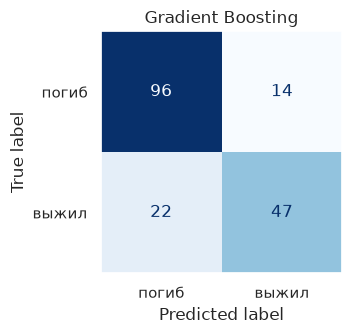

TN = 96, FP = 14, FN = 22, TP = 47


In [24]:
gb = gb_search.best_estimator_
evaluate("Gradient Boosting", gb, gb_search.best_score_)

,Decision Tree,Random Forest,Gradient Boosting
IsMale,0.0000,0.2516,0.2861
Title_Mr,0.6298,0.2156,0.3612
LogFare,0.0075,0.0907,0.0379
Pclass,0.1555,0.0820,0.1308
HasCabin,0.0504,0.0702,0.0630
Title_Miss,0.0000,0.0669,0.0000
Title_Mrs,0.0000,0.0572,0.0000
FamilySize,0.0825,0.0494,0.0715
Age,0.0130,0.0405,0.0430
SibSp,0.0000,0.0218,0.0009


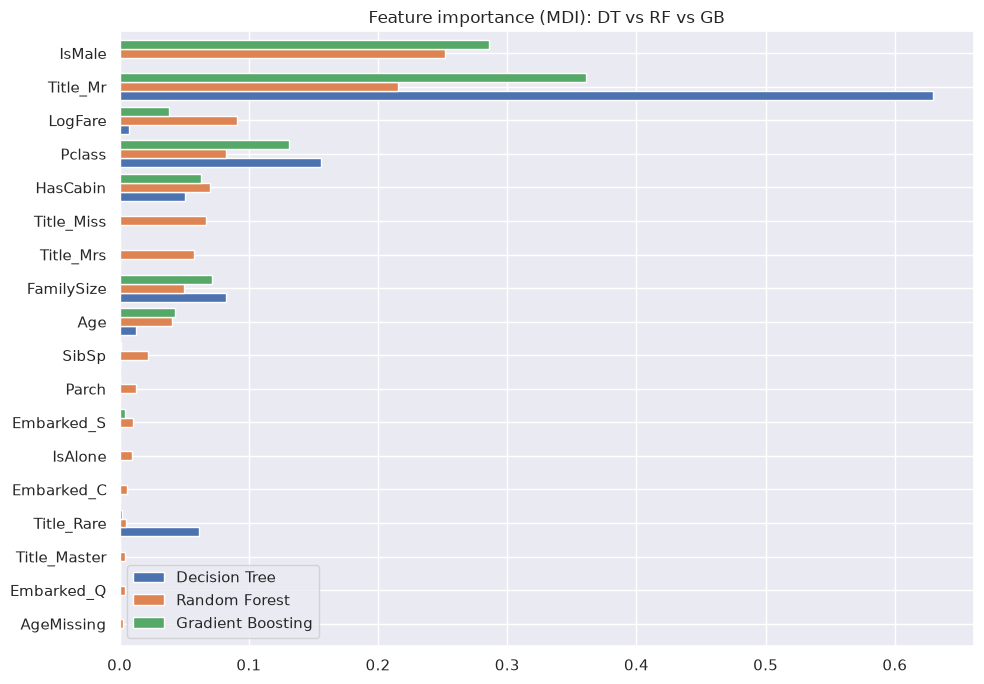

In [25]:
gb_imp = pd.Series(gb[-1].feature_importances_, index=FEATURES)
imp = pd.DataFrame({"Decision Tree": dt_imp, "Random Forest": rf_imp, "Gradient Boosting": gb_imp}).sort_values("Random Forest")
imp.plot.barh(figsize=(10, 7), width=0.8, title="Feature importance (MDI): DT vs RF vs GB")
plt.tight_layout()
imp.sort_values("Random Forest", ascending=False)

- С параметрами по умолчанию CV F1 0.750. После подбора (`learning_rate=0.02`, 100 деревьев глубины 2, `subsample=0.8`) 0.778 ± 0.042. Это довольно «слабый» бустинг: при маленьком шаге 100 деревьев - это мало. Более сильные варианты на CV хуже, они начинают подгоняться под шум.
- На тесте Accuracy 0.799, Precision 0.771, Recall 0.681, F1 0.723, порог пройден. Train F1 0.780, переобучения почти нет.
- **Сравнение с Random Forest**: качество почти одинаковое и на CV (0.778 и 0.780), и на тесте (0.723 и 0.733). На тесте они совпадают в 99.4% предсказаний (таблица согласия ниже), разница в одном пассажире. Обе модели выучили одно и то же правило.
- **Важность у бустинга** более сосредоточенная: `Title_Mr` 0.36, `IsMale` 0.29, `Pclass` 0.13, `FamilySize` 0.07, `HasCabin` 0.06, `Age` и `LogFare` по 0.04, а `Title_Miss`/`Title_Mrs` вообще 0. У бустинга нет случайного выбора признаков, поэтому он каждый раз берёт лучший сплит и не размазывает важность по похожим признакам, как лес. Первая пятёрка у всех трёх деревьев одна и та же, отличается только распределение весов внутри неё.

### 5.4 Support Vector Machine

SVM с RBF-ядром. Ядро считается через расстояние между объектами $K(x, x') = \exp(-\gamma\|x - x'\|^2)$, поэтому без масштабирования признак с большим разбросом (`Age`, десятки лет) забивает остальные (бинарные 0/1). Для проверки сравниваю на CV с масштабированием и без.

In [26]:
print("SVM без масштабирования: CV F1 = %.4f ± %.4f" % cv_f1(make_model(SVC(), scale=False)))
print("SVM с StandardScaler:    CV F1 = %.4f ± %.4f" % cv_f1(make_model(SVC(), scale=True)))

svm_search = tune(
    make_model(SVC(random_state=RANDOM_STATE), scale=True),
    {"model__C": [0.1, 0.3, 1, 3, 10, 30], "model__gamma": ["scale", 0.01, 0.03, 0.1, 0.3],
     "model__kernel": ["rbf"]},
)

SVM без масштабирования: CV F1 = 0.4353 ± 0.0370
SVM с StandardScaler:    CV F1 = 0.7643 ± 0.0342
Лучшие параметры: {'model__C': 1, 'model__gamma': 0.03, 'model__kernel': 'rbf'}  CV F1 = 0.7740 ± 0.0344


SVM: Accuracy = 0.8268, Precision = 0.7969, Recall = 0.7391, F1 = 0.7669
     train: Accuracy = 0.8413, F1 = 0.7839


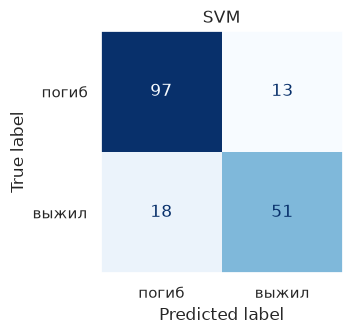

TN = 97, FP = 13, FN = 18, TP = 51


In [27]:
svm = svm_search.best_estimator_
evaluate("SVM", svm, svm_search.best_score_)

- Без масштабирования CV F1 0.435, с масштабированием 0.764. Разница огромная, это подтверждает то, что я писал выше: без масштабирования ядро смотрит почти только на `Age`, а пол и класс (0/1, 1-3) на расстояние почти не влияют.
- Подобрал `C=1`, `gamma=0.03` (довольно гладкая граница): CV F1 0.774 ± 0.034.
- На тесте Accuracy 0.827, Precision 0.797, Recall 0.739, F1 0.767, порог пройден. Это лучший Recall из всех моделей (нашёл 51 из 69 выживших). Train F1 0.784, разрыв с тестом маленький, переобучения нет.
- Встроенной важности признаков у SVM с RBF-ядром нет, поэтому её смотрю через permutation importance в разделе 7.

### 5.5 K-Nearest Neighbors

KNN относит объект к классу, который чаще всего встречается у k ближайших соседей из train. «Ближайших» - по евклидову расстоянию. Если признаки не масштабировать, расстояние почти целиком определяется `Age` (разброс ~14 лет), а разница в поле или классе (0/1, 1-3) почти ничего не значит. Тогда соседями будут просто пассажиры того же возраста.

KNN (k=5) без масштабирования: CV F1 = 0.6687 ± 0.0271
KNN (k=5) с StandardScaler:    CV F1 = 0.7386 ± 0.0149
Лучшие параметры: {'model__n_neighbors': 27, 'model__weights': 'distance'}  CV F1 = 0.7574 ± 0.0462


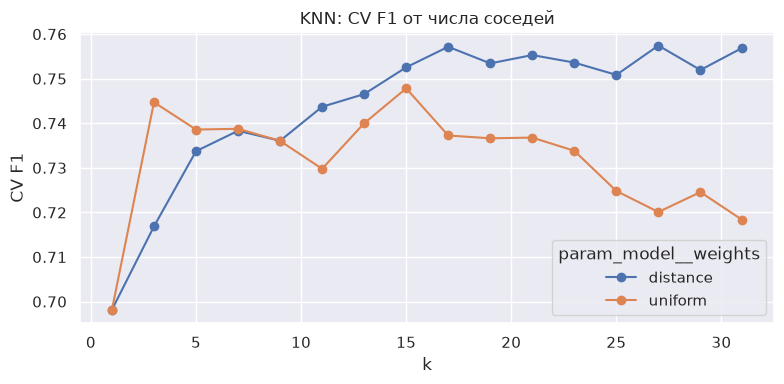

In [28]:
print("KNN (k=5) без масштабирования: CV F1 = %.4f ± %.4f" % cv_f1(make_model(KNeighborsClassifier(), scale=False)))
print("KNN (k=5) с StandardScaler:    CV F1 = %.4f ± %.4f" % cv_f1(make_model(KNeighborsClassifier(), scale=True)))

knn_search = tune(
    make_model(KNeighborsClassifier(), scale=True),
    {"model__n_neighbors": list(range(1, 32, 2)), "model__weights": ["uniform", "distance"]},
)
res = pd.DataFrame(knn_search.cv_results_)
ax = res.pivot_table(index="param_model__n_neighbors", columns="param_model__weights", values="mean_test_score") \
    .plot(marker="o", figsize=(8, 4), title="KNN: CV F1 от числа соседей")
ax.set_xlabel("k"); ax.set_ylabel("CV F1")
plt.tight_layout()

KNN: Accuracy = 0.8156, Precision = 0.7812, Recall = 0.7246, F1 = 0.7519
     train: Accuracy = 0.9874, F1 = 0.9833


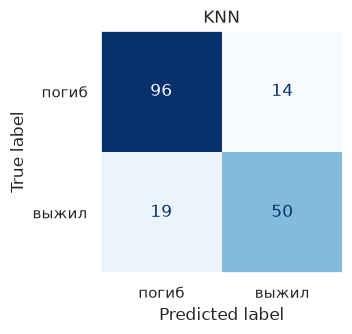

TN = 96, FP = 14, FN = 19, TP = 50


In [29]:
knn = knn_search.best_estimator_
evaluate("KNN", knn, knn_search.best_score_)

- k=5 без масштабирования: CV F1 0.669, с масштабированием 0.739. Масштаб для KNN важен, потому что он ищет соседей по расстоянию. Без масштабирования соседи - это просто люди того же возраста и с похожей ценой билета, независимо от пола и класса.
- Лучше всего `k=27`, `weights="distance"`: CV F1 0.757 ± 0.046. Маленькие k на графике заметно хуже - данные шумные, и голосование по нескольким соседям часто ошибается. Большое k сглаживает.
- На тесте Accuracy 0.816, Precision 0.781, Recall 0.725, F1 0.752, порог пройден.
- На train F1 0.983, но это не переобучение в обычном смысле: при `weights="distance"` сам объект из train - это сосед с расстоянием 0, и он всегда «голосует» за свой класс. Поэтому train-метрики у такого KNN смысла не имеют, смотрю на CV и тест.
- KNN хуже остальных на CV. Скорее всего потому, что все признаки в расстоянии равноправны: малополезные `Embarked_*`, `Parch`, `SibSp` вносят шум наравне с полом.

## 6. Честное сравнение моделей

Все модели учились на одном и том же train с одинаковой подготовкой (внутри Pipeline), параметры подбирались только по CV на train (одни и те же 5 фолдов), проверка на одном и том же test.

In [30]:
summary = pd.DataFrame(results).T
summary["F1 > 0.70"] = summary["F1"] > 0.70
summary["Train - Test F1"] = summary["Train F1"] - summary["F1"]
summary.index.name = "Модель"
summary.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,CV F1,Train Accuracy,Train F1,F1 > 0.70,Train - Test F1
Модель,,,,,,,,,
Decision Tree,0.8324,0.8197,0.7246,0.7692,0.7619,0.8315,0.7683,True,-0.0009
SVM,0.8268,0.7969,0.7391,0.7669,0.7740,0.8413,0.7839,True,0.0170
KNN,0.8156,0.7812,0.7246,0.7519,0.7574,0.9874,0.9833,True,0.2314
Random Forest,0.8045,0.7742,0.6957,0.7328,0.7800,0.8399,0.7824,True,0.0496
Decision Tree (без ограничений),0.7933,0.7353,0.7246,0.7299,0.7161,0.9874,0.9833,True,0.2534
Gradient Boosting,0.7989,0.7705,0.6812,0.7231,0.7776,0.8385,0.7801,True,0.0570
Baseline (most frequent),0.6145,0.0000,0.0000,0.0000,0.0000,0.6166,0.0000,False,0.0000


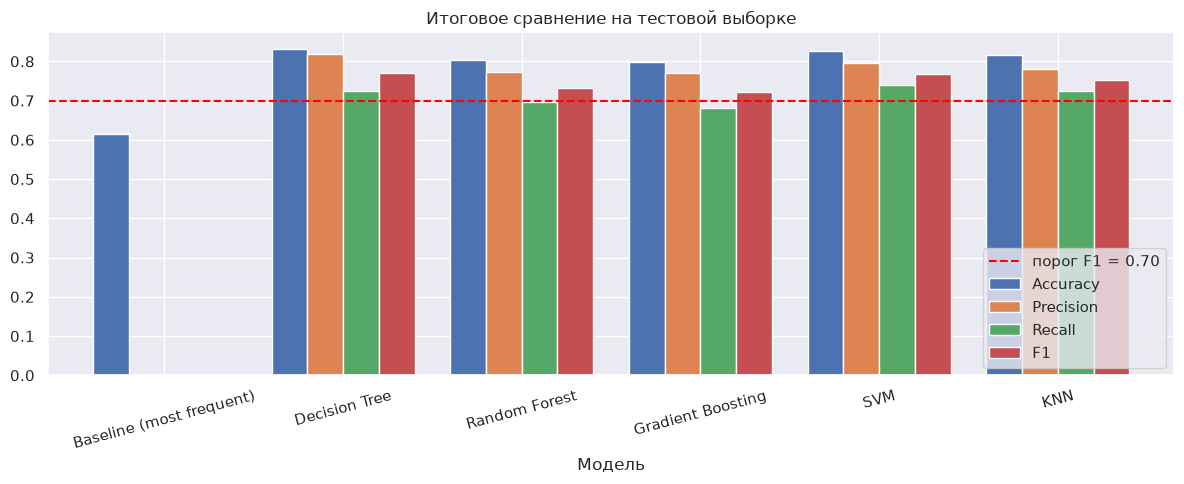

In [31]:
main_models = ["Baseline (most frequent)", "Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"]
ax = summary.loc[main_models, ["Accuracy", "Precision", "Recall", "F1"]].plot.bar(figsize=(12, 5), rot=15, width=0.8)
ax.axhline(0.70, color="red", ls="--", label="порог F1 = 0.70")
ax.legend(loc="lower right"); ax.set_title("Итоговое сравнение на тестовой выборке")
plt.tight_layout()

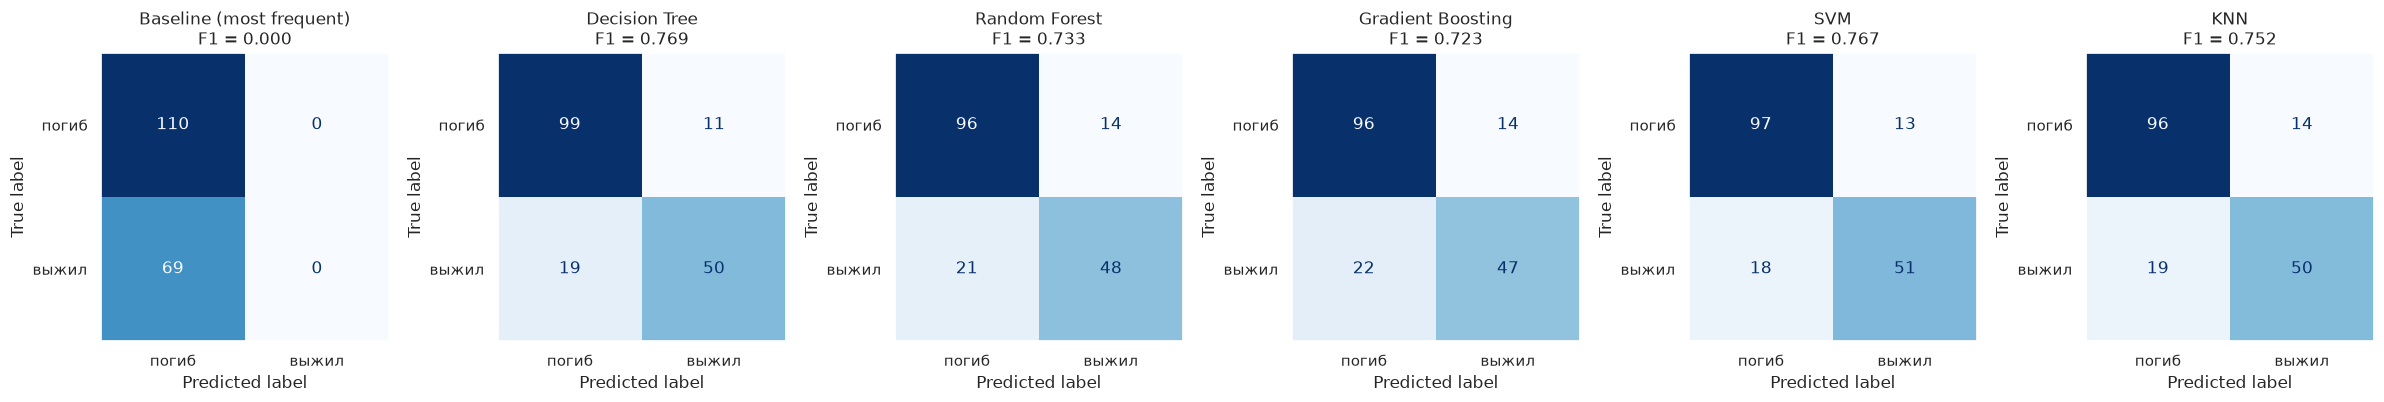

In [32]:
fig, axs = plt.subplots(1, 6, figsize=(24, 4))
for ax, name in zip(axs, main_models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, models[name].predict(X_test)),
                           display_labels=["погиб", "выжил"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nF1 = {summary.loc[name, 'F1']:.3f}"); ax.grid(False)
plt.tight_layout()

In [33]:
# насколько модели согласны между собой на тесте
preds = pd.DataFrame({name: models[name].predict(X_test) for name in main_models[1:]}, index=X_test.index)
agree = pd.DataFrame({a: {b: (preds[a] == preds[b]).mean() for b in preds} for a in preds})
print("Объектов, где все 5 моделей ошиблись:", (preds.ne(y_test, axis=0).all(axis=1)).sum(), "из", len(y_test))
agree.round(3)

Объектов, где все 5 моделей ошиблись: 26 из 179


,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
Decision Tree,1.000,0.961,0.955,0.972,0.939
Random Forest,0.961,1.000,0.994,0.978,0.922
Gradient Boosting,0.955,0.994,1.000,0.972,0.916
SVM,0.972,0.978,0.972,1.000,0.944
KNN,0.939,0.922,0.916,0.944,1.000


**Какие модели прошли порог F1 > 0.70?** Все пять: Decision Tree 0.769, SVM 0.767, KNN 0.752, Random Forest 0.733, Gradient Boosting 0.723. Baseline - 0. Неограниченное дерево тоже формально прошло (0.730), но оно сильно переобучено.

**Почему порядок на тесте и на CV разный?** На CV первые Random Forest (0.780) и бустинг (0.778), потом SVM (0.774), дерево (0.762), KNN (0.757). На тесте наоборот, дерево и SVM впереди. Разница между моделями на CV до 0.02, а std между фолдами 0.03-0.05. На тесте 179 пассажиров и 69 выживших, и дерево обгоняет лес всего на 2 угаданных выживших и 3 ложные тревоги. То есть по качеству модели практически одинаковые, и порядок на тесте во многом случаен. Поэтому выбирать модель по тесту нельзя (и не по правилам).

**Почему модели так похожи?** Все они в основном выучили одно правило: «мужчины погибают, женщины и дети 1-2 класса выживают, в 3 классе как повезёт, большие семьи погибают». Таблица согласия: RF и GB совпадают в 99.4% предсказаний, DT, RF и SVM - в 96-98%. Отличается только KNN (92-94%). На 26 из 179 пассажиров теста ошиблись **все** пять моделей - это люди, судьба которых противоречит своей группе (выживший мужчина 3 класса, погибшая женщина 1 класса). По этим признакам их не угадать, поэтому даже идеальное объединение этих моделей не дало бы Accuracy выше 0.85 (153 из 179).

**Откуда всё-таки различия:**
1. Неограниченное дерево запоминает шум, поэтому оно хуже всех. С ограничением глубины одно дерево получает почти то же, что и ансамбли, потому что главное правило простое и укладывается в 3 уровня.
2. Лес и бустинг дают более гладкие и стабильные границы, поэтому лучше на CV, но на маленьком датасете (712 объектов) большого выигрыша над деревом нет.
3. SVM с масштабированием строит гладкую нелинейную границу и получает лучший Recall.
4. KNN проигрывает, потому что в расстоянии все признаки весят одинаково, а половина из них малополезна.

**Precision выше Recall у всех моделей**: модели чаще пропускают выживших (FN), чем ошибочно «спасают» погибших (FP). Выживших меньше, и правило «мужчина -> погиб» не находит мужчин, которые всё-таки спаслись.

## 7. Feature importance

MDI считается на train и для коррелированных признаков (`IsMale` и `Title_Mr`, `SibSp`/`Parch`/`FamilySize`) делит важность между ними. Поэтому дополнительно считаю permutation importance на тесте: перемешиваю один **исходный** столбец (до подготовки) и смотрю, насколько падает F1. Так `Name` отвечает за `Title`, `Cabin` за `HasCabin`, `Sex` за `IsMale`, и можно сравнить все модели, включая SVM и KNN.

,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
Name,0.3794,0.1838,0.1424,0.3664,0.3236
Sex,0.0000,0.0931,0.1634,0.0132,0.0101
SibSp,0.0447,0.0405,0.0404,0.0481,0.0389
Age,0.0000,0.0082,-0.0006,0.0028,0.0219
Parch,0.0099,0.0061,0.0087,-0.0010,-0.0154
Embarked,0.0000,0.0003,0.0000,0.0057,0.0093
Pclass,0.0351,-0.0005,0.0180,0.0022,0.0141
Fare,0.0000,-0.0071,-0.0003,-0.0014,-0.0268
Cabin,0.0000,-0.0224,-0.0147,-0.0028,-0.0015


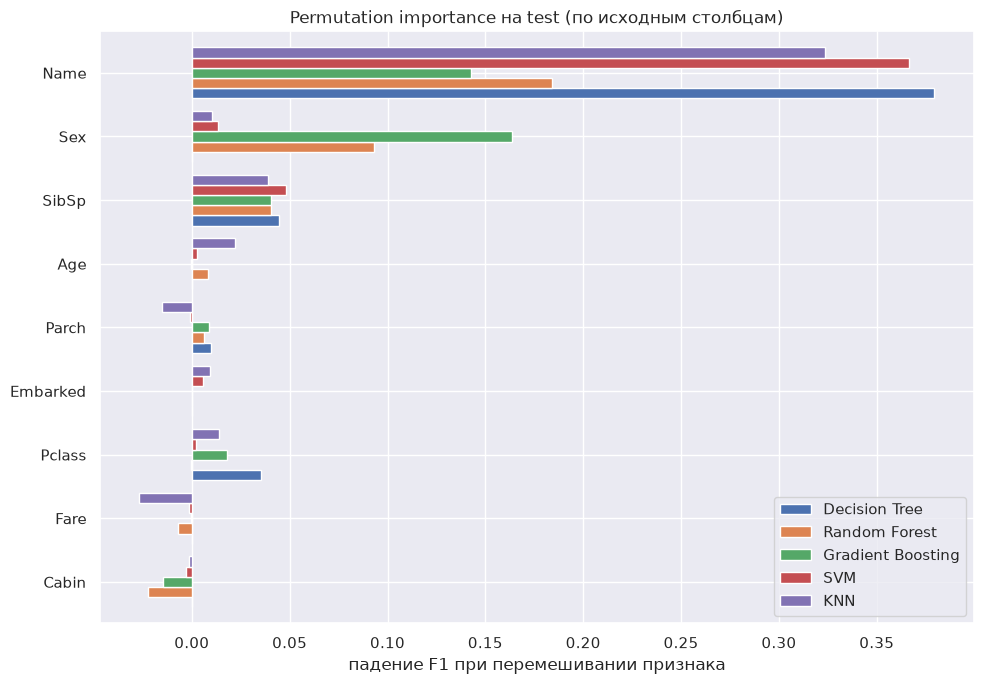

In [34]:
perm = {}
for name in main_models[1:]:
    r = permutation_importance(models[name], X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
                               scoring="f1", n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=RAW_COLS)
perm = pd.DataFrame(perm)

order = perm["Random Forest"].sort_values().index
perm.loc[order].plot.barh(figsize=(10, 7), width=0.8)
plt.xlabel("падение F1 при перемешивании признака")
plt.title("Permutation importance на test (по исходным столбцам)")
plt.tight_layout()
perm.loc[order[::-1]]

In [35]:
# ранги MDI (1 - самый важный)
mdi = pd.DataFrame({"Decision Tree": dt_imp, "Random Forest": rf_imp, "Gradient Boosting": gb_imp})
mdi.rank(ascending=False).astype(int).sort_values("Random Forest").head(10)

,Decision Tree,Random Forest,Gradient Boosting
IsMale,13,1,2
Title_Mr,1,2,1
LogFare,7,3,7
Pclass,2,4,3
HasCabin,5,5,5
Title_Miss,13,6,14
Title_Mrs,13,7,14
FamilySize,3,8,4
Age,6,9,6
SibSp,13,10,10


Выводы:
1. **У всех трёх деревьев на первом месте пол**: `Title_Mr` и `IsMale` вместе - это от 0.47 (RF) до 0.65 (GB) и 0.63 (DT) всей важности. Это совпадает с EDA: пол был самым сильным признаком (74% против 19%).
2. **Дальше класс и достаток**: `Pclass`, `HasCabin`, `LogFare`. Это тоже ожидаемо из EDA, и эти три признака сильно связаны между собой, поэтому модели делят важность между ними по-разному: DT и GB больше берут `Pclass`, RF больше `LogFare`.
3. **Потом семья и возраст**: `FamilySize` (у DT и GB 3-4 место) и `Age`. В EDA большие семьи почти все погибли, а дети выживали чаще.
4. **`Embarked` почти не важен** ни для одной модели, как я и предполагал в EDA: его связь с выживанием шла через класс.
5. **Permutation importance** (по исходным столбцам) для всех пяти моделей ставит на первое место `Name`, то есть `Title` (падение F1 от 0.14 до 0.38). Обращение одновременно говорит о поле и возрасте (Master - мальчик), поэтому оно сильнее, чем один пол. `Sex` сверху этого заметно добавляет только RF и GB (0.09 и 0.16), а для DT, SVM и KNN он почти ничего не значит - они берут пол из `Title`. Также у всех заметен `SibSp` (около 0.04) - через `FamilySize`.
6. `Pclass`, `Fare`, `Cabin`, `Age` по permutation importance около нуля. Это не значит, что они бесполезны: они дублируют друг друга (класс <-> цена <-> каюта), и если перемешать один, модель берёт ту же информацию из остальных. Отрицательные значения - это шум на маленьком тесте.

**Вопрос:** можно ли утверждать, что важный для модели признак является причиной выживания пассажира?

**Ответ:** нет. Важность показывает только, что модель использует этот признак для предсказания, то есть что в данных есть связь. Причину так установить нельзя. Например:
- `HasCabin` важен, но знание номера каюты никого не спасло. Это признак 1 класса (82% известных кают там), а 1 класс жил на верхних палубах ближе к шлюпкам. Возможно, к тому же номера кают чаще известны как раз у выживших (информацию собирали после катастрофы), тогда связь вообще обратная.
- `Fare` и `Embarked` связаны с выживанием через класс. Если бы пассажир 3 класса заплатил больше, ничего бы не изменилось.
- `Title` и `Sex` ближе всего к настоящей причине (правило «женщины и дети первыми»), но и тут модель не отделяет эффект пола от того, где находились каюты, с кем человек плыл и т.д.

Кроме того, важность зависит от модели и от способа подсчёта: у дерева `IsMale` = 0, а у бустинга 0.29, хотя информация одна и та же. Чтобы говорить о причинах, нужен эксперимент или специальный причинный анализ, а у нас просто наблюдения.

## 8. Анализ ошибок

Лучшую модель выбираю по CV F1 (не по тесту). Ошибки смотрю на тесте.

Лучшая модель по CV: Random Forest


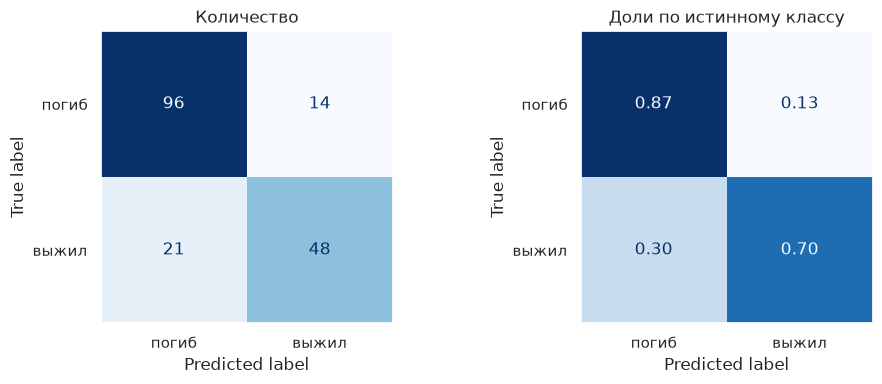

error
верно    144
FN        21
FP        14
Name: count, dtype: int64

In [36]:
best_name = summary.loc[main_models[1:], "CV F1"].idxmax()
best_model = models[best_name]
print("Лучшая модель по CV:", best_name)

err = df.loc[X_test.index].copy()
err["pred"] = best_model.predict(X_test)
err["error"] = np.select([err.pred > err[TARGET], err.pred < err[TARGET]], ["FP", "FN"], "верно")
cm = confusion_matrix(y_test, err["pred"])

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=["погиб", "выжил"]).plot(ax=axs[0], cmap="Blues", colorbar=False)
ConfusionMatrixDisplay(confusion_matrix(y_test, err["pred"], normalize="true"),
                       display_labels=["погиб", "выжил"]).plot(ax=axs[1], cmap="Blues", colorbar=False, values_format=".2f")
axs[0].set_title("Количество"); axs[1].set_title("Доли по истинному классу")
for ax in axs: ax.grid(False)
plt.tight_layout(); plt.show()
err["error"].value_counts()

In [37]:
def group_errors(by):
    g = err.groupby(by, observed=True)
    return pd.DataFrame({
        "n": g.size(),
        "выжило": g[TARGET].mean(),
        "предсказано выживших": g["pred"].mean(),
        "FP": g["error"].apply(lambda e: (e == "FP").sum()),
        "FN": g["error"].apply(lambda e: (e == "FN").sum()),
        "доля ошибок": g["error"].apply(lambda e: (e != "верно").mean()),
    }).round(3)

group_errors(["Sex", "Pclass"])

n  выжило  предсказано выживших  FP  FN  доля ошибок
Sex    Pclass                                                       
female 1       15   0.933                 1.000   1   0        0.067
       2       18   0.944                 1.000   1   0        0.056
       3       28   0.500                 0.821   9   0        0.321
male   1       30   0.367                 0.133   3  10        0.433
       2       16   0.188                 0.062   0   2        0.125
       3       72   0.139                 0.014   0   9        0.125

In [38]:
err["AgeGroup"] = pd.cut(err["Age"], [0, 12, 18, 30, 45, 80]).astype(str).replace("nan", "неизвестен")
err["Title"] = add_features(err)["Title"]
err["FamilySize"] = err["SibSp"] + err["Parch"] + 1
display(group_errors("Title"))
display(group_errors("AgeGroup"))
group_errors(pd.cut(err["FamilySize"], [0, 1, 4, 11], labels=["один", "2-4", "5+"]))

,n,выжило,предсказано выживших,FP,FN,доля ошибок
Title,,,,,,
Master,9,0.667,0.333,0,3,0.333
Miss,41,0.683,0.878,8,0,0.195
Mr,105,0.171,0.000,0,18,0.171
Mrs,19,0.842,1.000,3,0,0.158
Rare,5,0.200,0.800,3,0,0.600


,n,выжило,предсказано выживших,FP,FN,доля ошибок
AgeGroup,,,,,,
"(0.0, 12.0]",14,0.500,0.357,1,3,0.286
"(12.0, 18.0]",17,0.471,0.529,1,0,0.059
"(18.0, 30.0]",55,0.400,0.327,4,8,0.218
"(30.0, 45.0]",32,0.344,0.312,3,4,0.219
"(45.0, 80.0]",21,0.429,0.333,1,3,0.190


,n,выжило,предсказано выживших,FP,FN,доля ошибок
FamilySize,,,,,,
один,103,0.320,0.252,6,13,0.184
2-4,64,0.531,0.531,8,8,0.250
5+,12,0.167,0.167,0,0,0.000


In [39]:
# уверенность модели на ошибках (у SVM - расстояние до разделяющей поверхности)
score = best_model.predict_proba(X_test)[:, 1] if hasattr(best_model, "predict_proba") else best_model.decision_function(X_test)
err["score"] = score
show = ["Survived", "pred", "score", "Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin", "Embarked"]
print("Ложноположительные (предсказали «выжил», на самом деле погиб):")
display(err[err.error == "FP"].sort_values("score", ascending=False)[show].head(8))
print("Ложноотрицательные (предсказали «погиб», на самом деле выжил):")
err[err.error == "FN"].sort_values("score")[show].head(8)

Ложноположительные (предсказали «выжил», на самом деле погиб):


,Survived,pred,score,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
297,0,1,0.8957,1,"Allison, Miss. Helen Loraine",female,2.0,1,2,151.5500,C22 C26,S
199,0,1,0.7655,2,"Yrois, Miss. Henriette (""Mrs Harbeck"")",female,24.0,0,0,13.0000,NaN,S
502,0,1,0.7022,3,"O'Sullivan, Miss. Bridget Mary",female,NaN,0,0,7.6292,NaN,Q
501,0,1,0.6875,3,"Canavan, Miss. Mary",female,21.0,0,0,7.7500,NaN,Q
593,0,1,0.6622,3,"Bourke, Miss. Mary",female,NaN,0,2,7.7500,NaN,Q
245,0,1,0.6371,1,"Minahan, Dr. William Edward",male,44.0,2,0,90.0000,C78,Q
578,0,1,0.6202,3,"Caram, Mrs. Joseph (Maria Elias)",female,NaN,1,0,14.4583,NaN,C
745,0,1,0.6162,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,71.0000,B22,S


Ложноотрицательные (предсказали «погиб», на самом деле выжил):


,Survived,pred,score,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
271,1,0,0.1088,3,"Tornquist, Mr. William Henry",male,25.0,0,0,0.0000,NaN,S
804,1,0,0.1090,3,"Hedman, Mr. Oskar Arvid",male,27.0,0,0,6.9750,NaN,S
444,1,0,0.1116,3,"Johannesen-Bratthammer, Mr. Bernt",male,NaN,0,0,8.1125,NaN,S
146,1,0,0.1135,3,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,0,0,7.7958,NaN,S
570,1,0,0.1143,2,"Harris, Mr. George",male,62.0,0,0,10.5000,NaN,S
17,1,0,0.1219,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,13.0000,NaN,S
455,1,0,0.1336,3,"Jalsevac, Mr. Ivan",male,29.0,0,0,7.8958,NaN,C
553,1,0,0.1398,3,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,0,0,7.2250,NaN,C


In [40]:
# выживаемость в train у похожих пассажиров (тот же пол и класс)
tr = df.loc[X_train.index]
pd.DataFrame({
    "доля выживших в train": tr.groupby(["Sex", "Pclass"])[TARGET].mean(),
    "n в train": tr.groupby(["Sex", "Pclass"]).size(),
}).round(3)

доля выживших в train  n в train
Sex    Pclass                                  
female 1                       0.975         79
       2                       0.914         58
       3                       0.500        116
male   1                       0.370         92
       2                       0.152         92
       3                       0.135        275

Выводы:

- Лучшая модель по CV - Random Forest. На тесте 144 верных ответа, 21 FN и 14 FP. Модель находит 70% выживших (48 из 69) и правильно определяет 87% погибших (96 из 110), то есть **пропуски выживших (FN) встречаются чаще**, чем ложные «спасения».
- Модель фактически выучила правило «пол + класс»: всех женщин 1 и 2 класса она считает выжившими, а мужчин 2 и 3 класса почти всех погибшими (предсказано выживших 6% и 1.4%). Где это правило верно, там почти нет ошибок. Ошибки сосредоточены в группах, где правило не работает:
  - **женщины 3 класса**: выжила ровно половина, а модель «спасает» 82% - 9 из 14 FP, ошибается на 32% этой группы;
  - **мужчины 1 класса**: выжило 37%, модель «спасает» 13% - 10 FN и 3 FP, ошибается на 43% группы, это худшая группа;
  - **мужчины 2-3 класса**: выжило 14-19%, модель не находит почти никого из них - ещё 11 FN.

  В итоге **все 21 FN - мужчины**, а 11 из 14 FP - женщины.
- По `Title` хуже всего `Rare` (3 ошибки из 5): в эту группу попали и графини с леди (выжили), и врачи, священники, военные (в основном погибли). Модель «спасает» 80% группы, хотя выжили 20%. Отдельно 3 из 9 мальчиков (`Master`) ошибочно «похоронены».
- Одиночки дают 13 FN - это выжившие одинокие мужчины. Большие семьи (5+) без ошибок: выжили только 2 из 12, и модель их правильно определила.

Разбор отдельных ошибок:
- **297, Allison, Miss Helen Loraine** (FP, вероятность 0.90): девочка 2 лет, 1 класс, билет за 151.55. По признакам это самый «выживаемый» профиль, в train такие выживали в 97% случаев. На самом деле она погибла вместе с матерью. Модель здесь ничего сделать не может.
- **199, Yrois, Miss Henriette** (FP, 0.77): женщина 2 класса, плывёт одна. Женщины 2 класса выживали в 91% случаев, она исключение.
- **502, 501, 593 - O'Sullivan, Canavan, Bourke** (FP, 0.66-0.70): женщины 3 класса из Квинстауна с самыми дешёвыми билетами (около 7.7). Для женщин 3 класса шанс 50 на 50, а модель склоняется к «выжила», потому что пол весит больше всего.
- **245, Minahan, Dr.** и **745, Crosby, Capt.** (FP, около 0.62-0.64): мужчины 1 класса с обращением из `Rare`. Модель «спасает» их, потому что в `Rare` есть выжившие знатные женщины. Это минус моего объединения редких обращений - лучше было бы делить `Rare` ещё и по полу (хотя `IsMale` у модели есть, этого оказалось мало).
- **FN - Tornquist, Hedman, Johannesen-Bratthammer, Andersson и др.** (вероятность около 0.11): все - молодые мужчины 3 (реже 2) класса, едут одни с дешёвым билетом. В train такие выживали в 13-15% случаев. Модель правильно оценила шанс как низкий, но эти люди оказались в числе везучих. Что их спасло (где они были в момент удара, успели ли к шлюпке), в данных нет.

Итого, большинство ошибок - пассажиры, чья судьба не совпала с типичной для их группы. По имеющимся признакам их не отличить: напомню, 43 пассажира в датасете совпадают по всем признакам с кем-то, у кого противоположный исход.

### Нет ли утечки и признаков-идентификаторов

В модели нет `PassengerId`, `Ticket`, самого `Name` и номера каюты. Проверю, что было бы, если бы их добавили: к лучшей модели добавляю `PassengerId` и закодированный номер билета (`Ticket` как категорию, порядковым кодом). Ещё одна проверка - насколько `Title` (единственное, что берётся из имени) похож на идентификатор: смотрю размер групп.

In [41]:
def add_features_with_ids(data):
    d = add_features(data)
    d["PassengerId"] = data["PassengerId"]
    # номер билета - число в конце строки (у билетов вида LINE его нет -> 0)
    d["TicketNum"] = pd.to_numeric(data["Ticket"].str.extract(r"(\d+)$")[0], errors="coerce").fillna(0)
    return d


ID_COLS = ["PassengerId", "TicketNum"]
LEAK_COLS = RAW_COLS + ["PassengerId", "Ticket"]
X_leak_train, X_leak_test = df.loc[X_train.index, LEAK_COLS], df.loc[X_test.index, LEAK_COLS]

leak_rows, leak_imp = {}, {}
for name in [best_name, "Decision Tree (без ограничений)"]:
    m = Pipeline([("prep", make_prep(name in ("SVM", "KNN"), add_features_with_ids, ID_COLS)),
                  ("model", clone(models[name][-1]))])
    cv_leak = cross_val_score(m, X_leak_train, y_train, cv=cv, scoring="f1", n_jobs=-1).mean()
    m.fit(X_leak_train, y_train)
    leak_rows[name] = {"Train F1": summary.loc[name, "Train F1"], "CV F1": summary.loc[name, "CV F1"],
                       "Test F1": summary.loc[name, "F1"]}
    leak_rows[name + " + PassengerId, TicketNum"] = {
        "Train F1": f1_score(y_train, m.predict(X_leak_train)), "CV F1": cv_leak,
        "Test F1": f1_score(y_test, m.predict(X_leak_test))}
    if hasattr(m[-1], "feature_importances_"):
        leak_imp[name] = pd.Series(m[-1].feature_importances_, index=m[0].transform(X_leak_train.head()).columns)

display(pd.DataFrame(leak_rows).T)
print("MDI с идентификаторами (топ-6):")
display(pd.DataFrame(leak_imp).sort_values("Decision Tree (без ограничений)", ascending=False).head(6))
print("Размеры групп Title в train:", add_features(X_train)["Title"].value_counts().to_dict())

,Train F1,CV F1,Test F1
Random Forest,0.7824,0.7800,0.7328
"Random Forest + PassengerId, TicketNum",0.7863,0.7685,0.7385
Decision Tree (без ограничений),0.9833,0.7161,0.7299
"Decision Tree (без ограничений) + PassengerId, TicketNum",1.0000,0.6952,0.6765


MDI с идентификаторами (топ-6):


,Random Forest,Decision Tree (без ограничений)
Title_Mr,0.2371,0.3087
TicketNum,0.0548,0.1480
LogFare,0.0759,0.0990
PassengerId,0.0216,0.0973
Age,0.0371,0.0878
Pclass,0.0740,0.0780


Размеры групп Title в train: {'Mr': 412, 'Miss': 144, 'Mrs': 107, 'Master': 31, 'Rare': 18}


- **Random Forest + `PassengerId`, `TicketNum`**: на CV стало даже хуже (0.769 против 0.780), на тесте +0.006 (это один пассажир, шум). Лес с глубиной 4 не успевает запомнить отдельных пассажиров, но всё равно тратит сплиты на бессмысленные номера (`TicketNum` получил MDI 0.055, `PassengerId` 0.02).
- **Дерево без ограничений + идентификаторы**: на train F1 = 1.000 - теперь оно может различить даже пассажиров с одинаковыми признаками и разным исходом, просто по номеру. А на CV F1 падает с 0.716 до 0.695, на тесте с 0.730 до 0.677. `TicketNum` у него второй по важности (0.148), а `PassengerId` (0.097) важнее, чем `Pclass`. Это и есть бессмысленное запоминание объектов: дерево запоминает конкретных людей по номеру, а на новых людях это только мешает.
- В моих моделях таких признаков нет. `Title` - единственное, что берётся из имени, но это не идентификатор: самая маленькая группа (`Rare`) - 18 человек в train.
- Признаков с информацией «после события» (шлюпка, номер тела) в датасете нет. Единственное сомнение - `HasCabin`, если номера кают чаще известны у выживших. Но permutation importance у `Cabin` около нуля (и даже отрицательный), так что модель на него не опирается, а его вклад по MDI в основном дублирует класс.
- Ещё вопрос про нежелательную информацию: модель сильно опирается на пол. Здесь это оправдано - правило «женщины и дети первыми» действительно применялось при посадке в шлюпки, это не предвзятость модели, а то, как всё было. Но такую модель нельзя переносить на задачи, где решение по полу недопустимо.

Значит, высокое качество моделей получено не за счёт идентификаторов или утечки, а за счёт пола, возраста, класса и размера семьи.

## 9. Итог

| Модель | Accuracy | Precision | Recall | F1 (test) | CV F1 |
|---|---|---|---|---|---|
| Baseline (most frequent) | 0.6145 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| Decision Tree | 0.8324 | 0.8197 | 0.7246 | 0.7692 | 0.7619 |
| Random Forest | 0.8045 | 0.7742 | 0.6957 | 0.7328 | 0.7800 |
| Gradient Boosting | 0.7989 | 0.7705 | 0.6812 | 0.7231 | 0.7776 |
| SVM | 0.8268 | 0.7969 | 0.7391 | 0.7669 | 0.7740 |
| KNN | 0.8156 | 0.7812 | 0.7246 | 0.7519 | 0.7574 |

- `PassengerId`, `Name`, `Ticket` и номер каюты как есть не использую - это идентификаторы. Из имени беру обращение, из каюты - факт, что она известна. Пропуски `Age` заполняю медианой по обращению, всё обучается только на train внутри Pipeline.
- Baseline (всегда «погиб») даёт Accuracy 0.61 и F1 = 0.
- Порог F1 > 0.70 проходят все пять моделей. На тесте лучше всех дерево глубины 3 (0.769) и SVM (0.767), на CV - Random Forest (0.780). Разница между моделями меньше разброса на CV и на тесте, по сути они одинаковые. Финальной беру лучшую по CV - Random Forest.
- Масштабирование критично для SVM (CV F1 0.44 -> 0.76) и KNN (0.67 -> 0.74), деревьям не нужно.
- Главные признаки: пол (`Title`/`IsMale`), класс и связанные с ним `HasCabin`/`Fare`, размер семьи, возраст. Это связь, а не причина.
- Больше всего ошибок на женщинах 3 класса (модель их «спасает») и на мужчинах, особенно 1 класса (модель их «хоронит»). FN встречаются чаще, чем FP.

In [42]:
# финальная модель: обучаю лучшую модель на всех данных
# на вход DataFrame с исходными столбцами Titanic (Pclass, Name, Sex, Age, SibSp, Parch, Fare, Cabin, Embarked)
final_model = clone(best_model).fit(X, y)


def predict_survived(data: pd.DataFrame) -> np.ndarray:
    return final_model.predict(data[RAW_COLS])

predict_survived(X_test.head())

array([0, 0, 0, 0, 1])